# CBE 130 Lab 5: Coupled Differential Equations

Most chemical processes involve several species or state variables that change together, so their balances form systems of coupled ODEs. In this lab, we solve a two-variable predator-prey model and a three-species batch reactor with forward Euler, RK4, and `solve_ivp`.

## Learning Objectives

- Implement forward Euler and RK4 loops for coupled first-order ODE systems.
- Use `solve_ivp` to solve coupled ODEs with two and three dependent variables.
- Compare hand-coded integrators with `solve_ivp`.
- Interpret how changing one model coefficient changes an oscillating system.

## Setup

Run this cell once before working through the lab. NumPy supports the array and linear algebra calculations, Matplotlib creates the plots, and SciPy provides `solve_ivp`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Part 2: Predator-Prey Dynamics with `solve_ivp` and Euler

The classical Lotka-Volterra model describes a prey population $x(t)$ and a predator population $y(t)$:

$$\frac{dx}{dt} = \alpha x - \beta x y$$

$$\frac{dy}{dt} = -\delta y + \gamma x y$$

Here $\alpha$ is the prey growth rate, $\beta$ is the rate at which predators consume prey, $\gamma$ is the rate at which consumed prey produces new predators, and $\delta$ is the predator death rate. All four parameters are positive. Because of the product $xy$, the system is nonlinear and cannot be written in the form $d\mathbf{Y}/dt = A\mathbf{Y}$. The same coupled, nonlinear structure appears in autocatalytic reaction networks, where two intermediates can oscillate in the same way.

In this part, populations are measured in thousands of animals and time is measured in years.

### Question 2.1

Use the parameter values $\alpha = 1.0$ 1/year, $\beta = 0.10$ 1/(thousand animals year), $\gamma = 0.10$ 1/(thousand animals year), and $\delta = 1.5$ 1/year, with initial populations $x(0) = 10$ thousand and $y(0) = 5$ thousand. Simulate $0 \leq t \leq 50$ years on a fixed time grid with $\Delta t = 0.02$ years using two methods.

First, use `solve_ivp` with `t_eval` set to the fixed time grid. Second, use forward Euler on the same grid, with the updates

$$x_{n+1} = x_n + \Delta t \left(\alpha x_n - \beta x_n y_n\right)$$

$$y_{n+1} = y_n + \Delta t \left(-\delta y_n + \gamma x_n y_n\right)$$

Make three plots: $x(t)$ from both methods, $y(t)$ from both methods, and a phase portrait of $y$ versus $x$ from both methods. Print the minimum and maximum of $x$ and $y$ in thousands for each method. Describe the visible differences between the two solutions, and explain which method you would trust for predicting the peak predator population.

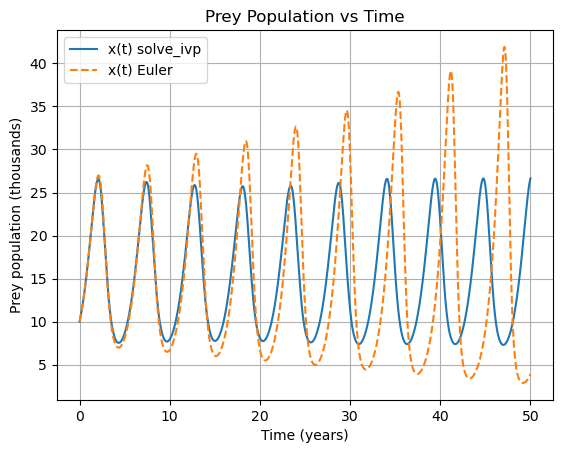

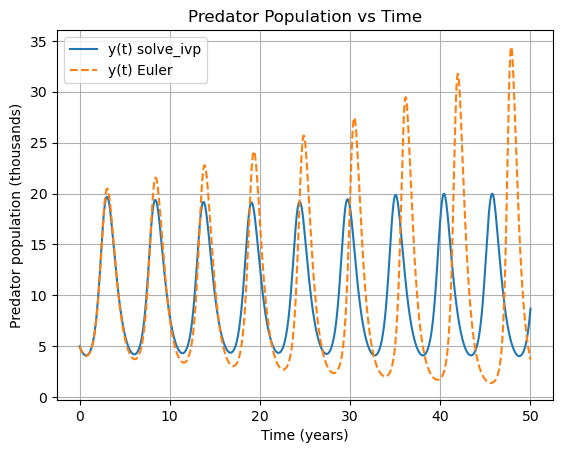

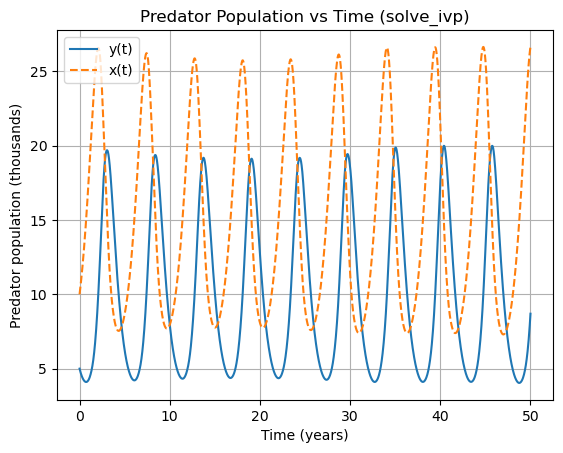

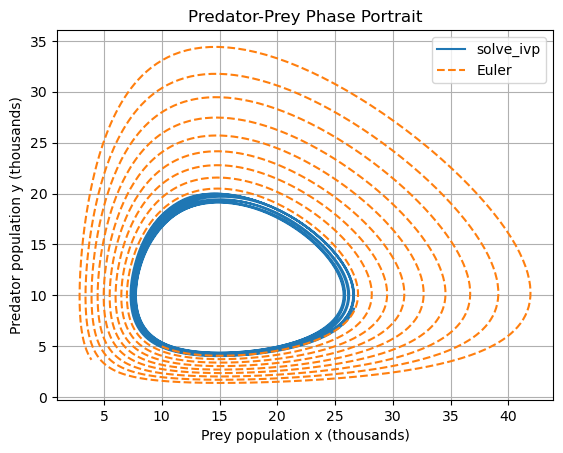

In [7]:
def predator_prey_rhs(t, population_values, alpha, beta, gamma, delta):
    x_current = population_values[0]  # prey population
    y_current = population_values[1]  # predator population
    dx_dt = alpha * x_current - beta * x_current * y_current
    dy_dt = -delta * y_current + gamma * x_current * y_current
    return np.array([dx_dt, dy_dt])

# Base-case parameters
alpha = 1.0   # prey growth rate (1/year)
beta = 0.10   # predation rate (1/(thousand animals year))
gamma = 0.10  # predator growth from eating prey (1/(thousand animals year))
delta = 1.5   # predator death rate (1/year)

x_initial = 10.0  # prey, thousands of animals
y_initial = 5.0   # predators, thousands of animals

t_initial = 0.0
t_final = 50.0
t_step = 0.02
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

# (i) solve_ivp on the fixed grid
solution = solve_ivp(
    predator_prey_rhs,
    (t_initial, t_final),
    [x_initial, y_initial],
    t_eval=t_values,
    args=(alpha, beta, gamma, delta)
)
solution_values = solution.y.T
x_ivp_values = solution_values[:, 0]
y_ivp_values = solution_values[:, 1]

# (ii) Forward Euler on the same grid
x_euler_values = np.zeros(len(t_values))
y_euler_values = np.zeros(len(t_values))

x_euler_values[0] = x_initial
y_euler_values[0] = y_initial

for index in range(len(t_values) - 1):
    x_current = x_euler_values[index]
    y_current = y_euler_values[index]
    slope_values = predator_prey_rhs(t_values[index], [x_current, y_current], alpha, beta, gamma, delta)
    x_euler_values[index + 1] = x_current + t_step * slope_values[0]
    y_euler_values[index + 1] = y_current + t_step * slope_values[1]

plt.figure()
plt.plot(t_values, x_ivp_values, label="x(t) solve_ivp")
plt.plot(t_values, x_euler_values, "--", label="x(t) Euler")
plt.title("Prey Population vs Time")
plt.xlabel("Time (years)")
plt.ylabel("Prey population (thousands)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(t_values, y_ivp_values, label="y(t) solve_ivp")
plt.plot(t_values, y_euler_values, "--", label="y(t) Euler")
plt.title("Predator Population vs Time")
plt.xlabel("Time (years)")
plt.ylabel("Predator population (thousands)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(t_values, y_ivp_values, label="y(t)")
plt.plot(t_values, x_ivp_values, "--", label="x(t)")
plt.title("Predator Population vs Time (solve_ivp)")
plt.xlabel("Time (years)")
plt.ylabel("Predator population (thousands)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(x_ivp_values, y_ivp_values, label="solve_ivp")
plt.plot(x_euler_values, y_euler_values, "--", label="Euler")
plt.title("Predator-Prey Phase Portrait")
plt.xlabel("Prey population x (thousands)")
plt.ylabel("Predator population y (thousands)")
plt.legend()
plt.grid(True)
plt.show()

`solve_ivp` gives a closed orbit that repeats every cycle. Forward Euler spirals outward because its error grows each cycle, and by 50 years it overpredicts the peak predator population (34.4 vs 20.0 thousand). `solve_ivp` is the one to trust.

### Question 2.2

Explore two alternative parameter sets, changing one coefficient at a time from the base case in Question 1.1:

- Case 1: increase the prey growth rate to $\alpha = 1.2$ 1/year.
- Case 2: increase the predation rate to $\beta = 0.12$ 1/(thousand animals year).

Use `solve_ivp` on the same fixed time grid with the same initial populations. For each case, plot $x(t)$ and $y(t)$ on one figure and print the minimum and maximum populations in thousands. Setting both derivatives to zero gives the nonzero equilibrium populations

$$x_{\mathrm{eq}} = \frac{\delta}{\gamma}, \qquad y_{\mathrm{eq}} = \frac{\alpha}{\beta}$$

Print the equilibrium for each case, estimate the oscillation period in years from the spacing between prey peaks, and compare the amplitude, period, and center of the oscillation with the base case.

Base case:
  x ranges from 7.30 to 26.64 thousand
  y ranges from 4.04 to 19.99 thousand
  Equilibrium: x = 15.00 thousand, y = 10.00 thousand


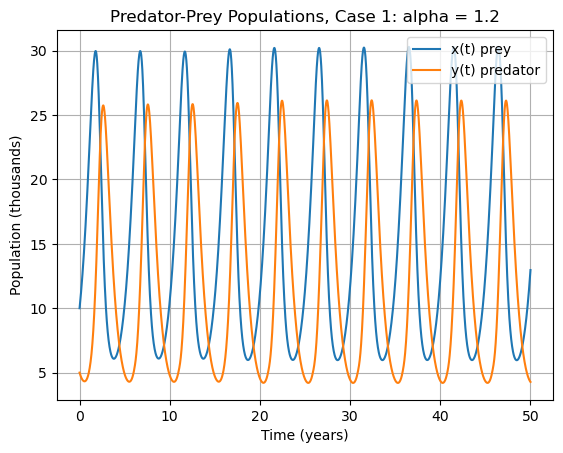

Case 1: alpha = 1.2:
  x ranges from 5.96 to 30.29 thousand
  y ranges from 4.20 to 26.14 thousand
  Equilibrium: x = 15.00 thousand, y = 12.00 thousand


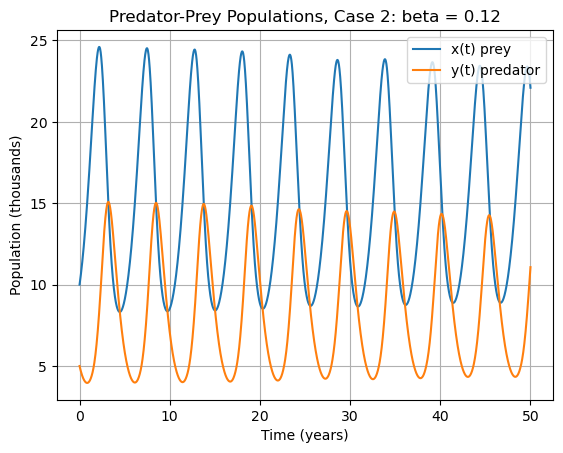

Case 2: beta = 0.12:
  x ranges from 8.32 to 24.60 thousand
  y ranges from 3.96 to 15.08 thousand
  Equilibrium: x = 15.00 thousand, y = 8.33 thousand


In [6]:
# Base case first, then change one coefficient at a time
case_names = ["Base case", "Case 1: alpha = 1.2", "Case 2: beta = 0.12"]
alpha_values = [1.0, 1.2, 1.0]
beta_values = [0.10, 0.10, 0.12]
gamma = 0.10
delta = 1.5

x_initial = 10.0
y_initial = 5.0
t_initial = 0.0
t_final = 50.0
t_step = 0.02
number_of_steps = int(round((t_final - t_initial) / t_step))
t_values = np.linspace(t_initial, t_final, number_of_steps + 1)

for case_index in range(len(case_names)):
    case_name = case_names[case_index]
    alpha = alpha_values[case_index]
    beta = beta_values[case_index]

    solution = solve_ivp(
        predator_prey_rhs,
        (t_initial, t_final),
        [x_initial, y_initial],
        t_eval=t_values,
        args=(alpha, beta, gamma, delta)
    )
    solution_values = solution.y.T
    x_case_values = solution_values[:, 0]
    y_case_values = solution_values[:, 1]

    # Nonzero equilibrium: both derivatives are zero
    x_equilibrium = delta / gamma
    y_equilibrium = alpha / beta

    if case_index > 0:
        plt.figure()
        plt.plot(t_values, x_case_values, label="x(t) prey")
        plt.plot(t_values, y_case_values, label="y(t) predator")
        plt.title(f"Predator-Prey Populations, {case_name}")
        plt.xlabel("Time (years)")
        plt.ylabel("Population (thousands)")
        plt.legend()
        plt.grid(True)
        plt.show()

    print(f"{case_name}:")
    print(f"  x ranges from {np.min(x_case_values):.2f} to {np.max(x_case_values):.2f} thousand")
    print(f"  y ranges from {np.min(y_case_values):.2f} to {np.max(y_case_values):.2f} thousand")
    print(f"  Equilibrium: x = {x_equilibrium:.2f} thousand, y = {y_equilibrium:.2f} thousand")

Increasing $\alpha$ raises the predator equilibrium to 12 thousand, makes the oscillations larger, and shortens the period to about 5.0 years. Increasing $\beta$ lowers the predator equilibrium to 8.3 thousand and makes the oscillations smaller, with little change in period. The prey equilibrium stays at 15 thousand in both cases.

## Part 3: Three-Species Batch Reactor

### Question 3.1

The series reaction $A \rightarrow B \rightarrow C$ takes place in a constant-volume batch reactor, with $k_{AB} = 0.50$ 1/min and $k_{BC} = 0.20$ 1/min. The mole balances are

$$\frac{dC_A}{dt} = -k_{AB} C_A$$

$$\frac{dC_B}{dt} = k_{AB} C_A - k_{BC} C_B$$

$$\frac{dC_C}{dt} = k_{BC} C_B$$

with $C_A(0) = 2.0$ mol/L and $C_B(0) = C_C(0) = 0$ mol/L. Solve for $0 \leq t \leq 20$ min using an RK4 loop with $\Delta t = 0.5$ min, and use `solve_ivp` on the same time grid. Plot all three concentrations from both methods on one figure, and print the final concentrations in mol/L.

For the state vector $Y_n = [C_{A,n}, C_{B,n}, C_{C,n}]^T$, the RK4 update is

$$k_1 = F(t_n, Y_n), \qquad k_2 = F\left(t_n + \frac{\Delta t}{2}, Y_n + \frac{\Delta t}{2} k_1\right)$$

$$k_3 = F\left(t_n + \frac{\Delta t}{2}, Y_n + \frac{\Delta t}{2} k_2\right), \qquad k_4 = F\left(t_n + \Delta t, Y_n + \Delta t\, k_3\right)$$

$$Y_{n+1} = Y_n + \frac{\Delta t}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Final RK4 concentrations: C_A = 0.0001, C_B = 0.0609, C_C = 1.9390 mol/L
Final solve_ivp concentrations: C_A = 0.0001, C_B = 0.0609, C_C = 1.9390 mol/L


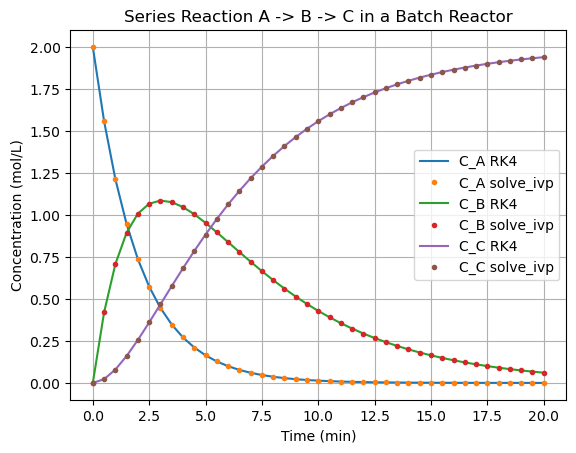

In [4]:
def F(t, C_values, k_AB, k_BC):
    C_A = C_values[0]
    C_B = C_values[1]
    dC_A_dt = -k_AB * C_A
    dC_B_dt = k_AB * C_A - k_BC * C_B
    dC_C_dt = k_BC * C_B
    return np.array([dC_A_dt, dC_B_dt, dC_C_dt])

k_AB = 0.50  # 1/min
k_BC = 0.20  # 1/min
t_initial = 0.0
t_final = 20.0
t_step = 0.5
t_values = np.arange(t_initial, t_final + t_step / 2.0, t_step)
IC = np.array([2.0, 0.0, 0.0])  # [C_A, C_B, C_C] at t = 0 in mol/L

# RK4 loop: each row stores [C_A, C_B, C_C] at one time
C_values_rk4 = np.zeros((len(t_values), 3))
C_values_rk4[0] = IC

for index in range(len(t_values) - 1):
    t_current = t_values[index]
    C_current = C_values_rk4[index]

    k1 = F(t_current, C_current, k_AB, k_BC)
    k2 = F(t_current + t_step / 2.0, C_current + t_step * k1 / 2.0, k_AB, k_BC)
    k3 = F(t_current + t_step / 2.0, C_current + t_step * k2 / 2.0, k_AB, k_BC)
    k4 = F(t_current + t_step, C_current + t_step * k3, k_AB, k_BC)
    C_next = C_current + (t_step / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    C_values_rk4[index + 1] = C_next

# solve_ivp on the same time grid
solution = solve_ivp(
    F,
    (t_initial, t_final),
    IC,
    method="RK45",
    t_eval=t_values,
    args=(k_AB, k_BC),
)
C_values_solve_ivp = solution.y.T

print(f"Final RK4 concentrations: C_A = {C_values_rk4[-1, 0]:.4f}, C_B = {C_values_rk4[-1, 1]:.4f}, C_C = {C_values_rk4[-1, 2]:.4f} mol/L")
print(f"Final solve_ivp concentrations: C_A = {C_values_solve_ivp[-1, 0]:.4f}, C_B = {C_values_solve_ivp[-1, 1]:.4f}, C_C = {C_values_solve_ivp[-1, 2]:.4f} mol/L")

plt.figure()
plt.plot(t_values, C_values_rk4[:, 0], label="C_A RK4")
plt.plot(t_values, C_values_solve_ivp[:, 0], "o", markersize=3, label="C_A solve_ivp")
plt.plot(t_values, C_values_rk4[:, 1], label="C_B RK4")
plt.plot(t_values, C_values_solve_ivp[:, 1], "o", markersize=3, label="C_B solve_ivp")
plt.plot(t_values, C_values_rk4[:, 2], label="C_C RK4")
plt.plot(t_values, C_values_solve_ivp[:, 2], "o", markersize=3, label="C_C solve_ivp")
plt.title("Series Reaction A -> B -> C in a Batch Reactor")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

The RK4 and `solve_ivp` results overlap. A is used up, the intermediate B rises to a maximum at about 3 min and then decays, and C approaches 2.0 mol/L.